# Step 5 - Explainability with SHAP
**Objective 3:** find out *why* the churn model rates a customer as risky, for the whole customer base and for each individual customer, and state the findings as plain behavioural rules.

**Input:** `data/churn_dataset.csv`, `data/feature_dictionary.csv`, `data/churn_predictions_test.csv` and the saved model `models/churn_models.joblib` from Step 4. Click **Run All** (about 3 minutes).

| Part | What happens |
|---|---|
| Model | The model Step 4 picked by cross-validation (`bundle["best"]`), explained on the **test snapshot (1 Jul 2011)**, exactly as it produces `ChurnProbability` |
| SHAP | Each customer's churn probability is split into one contribution per feature. Contributions **add up**: `typical probability + sum of contributions = this customer's probability` |
| Global view | Which features matter most overall, in which direction, and how SHAP compares with permutation importance |
| Local view | Waterfall charts and plain-English reasons for individual customers |
| Sanity checks | The SHAP calculation is checked against an exact answer; logistic regression is used as a second opinion on the direction of every effect |

**Outputs:** `data/shap_values_test.csv`, `data/shap_feature_importance.csv`, `data/shap_top_drivers_test.csv` (reasons per customer, for Step 8 and the dashboard), `shap_summary.txt`, and charts `figures/shap_*.png`.

### How to read a SHAP value
A SHAP value is a feature's **push on the churn probability, in percentage points (pp)**, compared with a typical customer. `+12 pp` for Recency means "this customer's time since last purchase makes the model 12 points more worried than for a typical customer"; `-8 pp` means it makes the model 8 points *less* worried.

### About the SHAP calculation
SHAP values are Shapley values from game theory: a feature's average marginal effect when features are switched from a typical customer's value to this customer's value, over all orders of switching. This notebook estimates them by **random sampling** (permutation SHAP with a background of 200 training customers, using forward and reversed orders to reduce noise). It is the same quantity the `shap` library's `PermutationExplainer` computes, works for any model (including scikit-learn's boosting, which the library's fast tree method does not support in all versions), and needs no extra installation. Section 11 optionally cross-checks it with the `shap` library if you have it installed.

## 1. Setup and data

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score
from IPython.display import display

warnings.filterwarnings("ignore")
pd.options.display.float_format = "{:,.3f}".format
pd.options.display.max_columns = 40
pd.options.display.max_colwidth = 110
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

DATA, FIG, MODELS = Path("data"), Path("figures"), Path("models")
FIG.mkdir(exist_ok=True)
SEED = 42

N_BACKGROUND = 200   # training customers used as the "typical customer" reference
N_PAIRS = 60         # random orderings per customer for the global run (more = less noise, slower)
N_LOCAL = 1000       # random orderings per customer for the individual explanations


def add_flags(df):
    """Same helper as Step 4: flags for customers who have no purchase-gap history."""
    df = df.copy()
    df["GapMissing"] = df["AvgGapDays"].isna().astype(int)
    df["StdGapMissing"] = df["StdGapDays"].isna().astype(int)
    return df


data = add_flags(pd.read_csv(DATA / "churn_dataset.csv", parse_dates=["SnapshotDate", "WindowEnd"]))
train = data[data["Split"] == "train"].reset_index(drop=True)
test = data[data["Split"] == "test"].reset_index(drop=True)
churn = pd.read_csv(DATA / "churn_predictions_test.csv")
fdict = pd.read_csv(DATA / "feature_dictionary.csv")
describe = dict(zip(fdict["column"], fdict["description"]))

LOG_COLS = ["Recency", "Frequency", "Monetary", "AvgOrderValue", "AvgGapDays", "StdGapDays", "RecencyGapRatio",
            "Orders90", "Spend90", "DistinctProducts", "AvgItemsPerOrder", "AvgLinesPerOrder",
            "ReturnCount", "Tenure", "PurchaseRate"]
PASS_COLS = ["OrdersTrend", "SpendTrend", "ReturnRate", "IsUK", "GapMissing", "StdGapMissing"]
CAT_COLS = ["Country"]
X_COLS = LOG_COLS + PASS_COLS + CAT_COLS          # the 22 model inputs used in Step 4

assert (churn["CustomerID"].to_numpy() == test["CustomerID"].to_numpy()).all(), "test rows differ from churn_predictions_test.csv"
print(f"Train: {len(train):,} rows   Test: {len(test):,} customers (snapshot {test['SnapshotDate'].iloc[0]:%d %b %Y}), churn rate {test['Churn'].mean():.1%}")

Train: 14,338 rows   Test: 4,313 customers (snapshot 01 Jul 2011), churn rate 45.7%


## 2. Load the Step 4 model

The model is loaded from `models/churn_models.joblib`, so the explanation is of **exactly** the model that produced `ChurnProbability`. If that file is missing (or was saved with a different scikit-learn version and cannot be opened), the notebook retrains the two models it needs with the best settings printed by Step 4 and says so. A retrained copy is very close but not identical, so use the saved file for the final report.

In [2]:
def make_prep(linear):
    """Identical to Step 4."""
    if linear:
        num = Pipeline([("imp", SimpleImputer(strategy="median")),
                        ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                        ("sc", StandardScaler())])
        pas = Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())])
    else:
        num = SimpleImputer(strategy="median")
        pas = "passthrough"
    cat = OneHotEncoder(handle_unknown="ignore", min_frequency=100, sparse_output=False)
    return ColumnTransformer([("num", num, LOG_COLS), ("pas", pas, PASS_COLS), ("cat", cat, CAT_COLS)])


def retrain_bundle():
    """Fallback: rebuild the logistic regression and the gradient boosting model with Step 4's best settings."""
    X, y = train[X_COLS], train["Churn"].to_numpy()
    lr = Pipeline([("prep", make_prep(True)), ("clf", LogisticRegression(max_iter=3000, random_state=SEED, C=0.1))]).fit(X, y)
    gb = Pipeline([("prep", make_prep(False)),
                   ("clf", HistGradientBoostingClassifier(random_state=SEED, min_samples_leaf=20, max_iter=300, max_depth=3,
                                                          learning_rate=0.03, l2_regularization=10))]).fit(X, y)
    entry = lambda p: {"pipeline": p, "method": "none", "calibrator": None, "threshold": np.nan}
    return {"best": "Gradient Boosting (sklearn)", "features": X_COLS,
            "models": {"Logistic Regression": entry(lr), "Gradient Boosting (sklearn)": entry(gb)}}


bundle, source = None, None
if (MODELS / "churn_models.joblib").exists():
    try:
        bundle = joblib.load(MODELS / "churn_models.joblib")
        source = "saved model models/churn_models.joblib"
    except Exception as e:
        print("Could not open models/churn_models.joblib:", type(e).__name__, str(e)[:150])
if bundle is None:
    bundle = retrain_bundle()
    source = "RETRAINED copy of the Step 4 models (models/churn_models.joblib was not found or could not be opened)"

BEST = bundle["best"]
best_entry = bundle["models"][BEST]
lr_pipe = bundle["models"]["Logistic Regression"]["pipeline"]
print(f"Model explained : {BEST}")
print(f"Model source    : {source}")


def _logit(s):
    s = np.clip(s, 1e-6, 1 - 1e-6)
    return np.log(s / (1 - s))


def churn_probability(entry, df):
    """Final churn probability exactly as in Step 4 / churn_scoring.py (model score, then calibration, then clip)."""
    s = entry["pipeline"].predict_proba(add_flags(df)[X_COLS])[:, 1]
    if entry["method"] == "isotonic":
        p = entry["calibrator"].predict(s)
    elif entry["method"] == "sigmoid":
        p = entry["calibrator"].predict_proba(_logit(s).reshape(-1, 1))[:, 1]
    else:
        p = s
    return np.clip(p, 0.001, 0.999)


p_model = churn_probability(best_entry, test)
diff = np.abs(p_model - churn["ChurnProbability"].to_numpy())
print(f"\nCheck against churn_predictions_test.csv: max difference {diff.max():.2g}, correlation {np.corrcoef(p_model, churn['ChurnProbability'])[0, 1]:.4f}")
print(f"Test ROC-AUC of the explained model: {roc_auc_score(test['Churn'], p_model):.3f}   (Step 4 file: {roc_auc_score(test['Churn'], churn['ChurnProbability']):.3f})")
if diff.max() < 1e-6:
    print("-> identical to the Step 4 predictions  ✓")
else:
    print("-> not identical to the Step 4 predictions (retrained copy, different scikit-learn version, or a changed model); use the original models/churn_models.joblib for exact results")

Model explained : Gradient Boosting (sklearn)
Model source    : RETRAINED copy of the Step 4 models (models/churn_models.joblib was not found or could not be opened)

Check against churn_predictions_test.csv: max difference 0.062, correlation 0.9991
Test ROC-AUC of the explained model: 0.775   (Step 4 file: 0.775)
-> not identical to the Step 4 predictions (retrained copy, different scikit-learn version, or a changed model); use the original models/churn_models.joblib for exact results


## 3. What exactly is explained

The model takes 22 inputs, but some are not independent: `GapMissing` / `StdGapMissing` only say whether `AvgGapDays` / `StdGapDays` exist, and `IsUK` is just `Country == United Kingdom`. If SHAP switched such pairs separately it would create impossible customers. So the explanation works on **19 features**: the 18 numeric inputs, where a missing purchase-gap history counts as part of the gap feature, and `Country` (which includes `IsUK`). The helper below turns a 19-column array back into the 22 model inputs and gives the model's churn probability.

In [3]:
EXPL_NUM = LOG_COLS + ["OrdersTrend", "SpendTrend", "ReturnRate"]
FEATS = EXPL_NUM + ["Country"]                 # the 19 explained features
D = len(FEATS)
LEVELS = np.array(sorted(data["Country"].unique()))
LEVEL_IX = {c: i for i, c in enumerate(LEVELS)}

FRIENDLY = {"Recency": "time since the last purchase", "Frequency": "number of orders", "Monetary": "total spend",
            "AvgOrderValue": "average order value", "AvgGapDays": "average gap between orders",
            "StdGapDays": "irregularity of the gaps between orders", "RecencyGapRatio": "how overdue the customer is (recency / usual gap)",
            "Orders90": "orders in the last 90 days", "Spend90": "spend in the last 90 days",
            "OrdersTrend": "trend in orders (recent vs previous 90 days)", "SpendTrend": "trend in spend",
            "DistinctProducts": "number of different products bought", "AvgItemsPerOrder": "units per order",
            "AvgLinesPerOrder": "different products per order", "ReturnRate": "return rate", "ReturnCount": "number of returns",
            "Tenure": "customer age (days since first purchase)", "PurchaseRate": "orders per 30 days", "Country": "country"}
assert set(FRIENDLY) == set(FEATS)


def to_array(df):
    """DataFrame -> (n x 19) float array; the last column is the country code."""
    Z = np.empty((len(df), D))
    Z[:, :D - 1] = df[EXPL_NUM].to_numpy(dtype=float)
    Z[:, D - 1] = df["Country"].map(LEVEL_IX).to_numpy()
    return Z


def to_frame(Z):
    """(n x 19) array -> the 22 model inputs (flags and IsUK are derived, so they always stay consistent)."""
    df = pd.DataFrame(Z[:, :D - 1], columns=EXPL_NUM)
    df["Country"] = LEVELS[Z[:, D - 1].astype(int)]
    df["IsUK"] = (df["Country"] == "United Kingdom").astype(int)
    return add_flags(df)[X_COLS]


def f_model(Z):
    """Churn probability (what we explain)."""
    return churn_probability(best_entry, to_frame(Z))


Z_train, Z_test = to_array(train), to_array(test)
assert np.abs(f_model(Z_test) - p_model).max() < 1e-9, "array round-trip changes the predictions"
print(f"{D} explained features; array round-trip reproduces the model's probabilities exactly  ✓")

# background = the "typical customer" reference: a random sample of training customers
rng = np.random.default_rng(SEED)
B = Z_train[rng.choice(len(Z_train), N_BACKGROUND, replace=False)]
BASE = f_model(B).mean()
print(f"Background: {N_BACKGROUND} training customers; their average churn probability is {BASE:.3f}")

19 explained features; array round-trip reproduces the model's probabilities exactly  ✓
Background: 200 training customers; their average churn probability is 0.480


## 4. The SHAP calculator

For each customer the function repeats the following `n_pairs` times: pick a random typical customer from the background, pick a random order of the features, then switch the features one by one from the typical customer's value to *this* customer's value. Each time, the change in the model's churn probability is credited to the feature just switched. The same is done with the order reversed (which cancels much of the random noise). Averaging over many repeats gives each feature's SHAP value.

Two properties are used as tests below:
1. **Additivity (exact):** the contributions always sum to *this customer's probability minus the typical customer's probability*.
2. **Correctness:** for a model where the true answer is known exactly (logistic regression), the calculator must reproduce it.

In [4]:
def shapley_sampling(f, X, B, n_pairs=60, seed=0):
    """Permutation-sampling SHAP values (interventional, with a background set B).

    f       : function from an (n x d) array to n model outputs
    X       : (n x d) customers to explain
    B       : (m x d) background customers (m >= n_pairs); each customer uses n_pairs DIFFERENT backgrounds
    returns : phi (n x d) SHAP values, se (n x d) Monte-Carlo standard errors, base (n,) expected output of the sampled backgrounds
              so that  f(X) = base + phi.sum(axis=1)  exactly.
    """
    rng = np.random.default_rng(seed)
    n, d = X.shape
    assert 2 <= n_pairs <= len(B)
    rows = np.arange(n)
    bg_pick = np.argsort(rng.random((n, len(B))), axis=1)[:, :n_pairs]      # distinct backgrounds per customer
    total = np.zeros((n, d))
    total_sq = np.zeros((n, d))
    base = np.zeros(n)
    for t in range(n_pairs):
        bg = B[bg_pick[:, t]]
        perm = np.argsort(rng.random((n, d)), axis=1)                        # a random feature order per customer
        f_bg = f(bg)
        base += f_bg
        est = np.zeros((n, d))
        for order in (perm, perm[:, ::-1]):                                  # forward and reversed order
            Z, prev = bg.copy(), f_bg
            for k in range(d):
                j = order[:, k]
                Z[rows, j] = X[rows, j]                                      # switch feature j to this customer's value
                cur = f(Z)
                est[rows, j] += (cur - prev) / 2                             # credit the change to feature j
                prev = cur
        total += est
        total_sq += est ** 2
    phi = total / n_pairs
    var = (total_sq / n_pairs - phi ** 2) * n_pairs / (n_pairs - 1)
    return phi, np.sqrt(np.maximum(var, 0) / n_pairs), base / n_pairs

## 5. Check the calculator against an exact answer

A logistic regression is *additive* in the features, so its exact SHAP values can be written down: a feature's value is the average change in the model output when only that feature is moved from the background value to the customer's value. With the same background customers used once each, the sampling calculator must give exactly the same numbers. This is run on the log-odds output of the logistic regression from Step 4 (100 customers, 40 background customers).

In [5]:
f_lr = lambda Z: lr_pipe.decision_function(to_frame(Z))       # log-odds of the logistic regression

chk_X, chk_B = Z_test[:100], B[:40]
phi_s, _, base_s = shapley_sampling(f_lr, chk_X, chk_B, n_pairs=len(chk_B), seed=SEED)

# exact answer for an additive model, computed a completely different way
f_B = f_lr(chk_B)
exact = np.zeros_like(phi_s)
for j in range(D):
    Zrep = np.tile(chk_B, (len(chk_X), 1))
    Zrep[:, j] = np.repeat(chk_X[:, j], len(chk_B))
    exact[:, j] = (f_lr(Zrep) - np.tile(f_B, len(chk_X))).reshape(len(chk_X), len(chk_B)).mean(axis=1)

err = np.abs(phi_s - exact).max()
eff = np.abs(phi_s.sum(axis=1) - (f_lr(chk_X) - base_s)).max()
print(f"Largest difference from the exact SHAP values : {err:.2e}")
print(f"Largest additivity error (sum vs prediction)  : {eff:.2e}")
print("Calculator check passed  ✓" if err < 1e-6 and eff < 1e-6 else "WARNING: check failed - do not trust the SHAP results below")

Largest difference from the exact SHAP values : 6.66e-16
Largest additivity error (sum vs prediction)  : 8.88e-16
Calculator check passed  ✓


## 6. SHAP values for all test customers

This is the longest step (about 2 minutes). `N_PAIRS` controls the accuracy: the standard error printed afterwards is the random-sampling noise of a single customer's single feature value; it shrinks with more repeats and averages out further in the global summaries.

In [6]:
import time
t0 = time.time()
phi, se, base_row = shapley_sampling(f_model, Z_test, B, n_pairs=N_PAIRS, seed=SEED)
print(f"Computed SHAP values for {len(Z_test):,} customers x {D} features in {time.time() - t0:.0f}s")

# test 1: additivity must hold exactly
add_err = np.abs(phi.sum(axis=1) + base_row - p_model).max()
print(f"Additivity: base value + sum of SHAP values equals the model's probability (max error {add_err:.1e})")
assert add_err < 1e-9

pp = phi * 100                                           # percentage points of churn probability
print(f"Typical customer (base value): {base_row.mean():.3f}   test customers' average probability: {p_model.mean():.3f}")
print(f"Typical size of one feature's contribution: {np.abs(pp).mean():.2f} pp;  Monte-Carlo noise (standard error): {se.mean() * 100:.2f} pp per value")
print(f"Noise in a global average (mean |SHAP| over {len(Z_test):,} customers): about {se.mean() * 100 / np.sqrt(len(Z_test)):.3f} pp")

Computed SHAP values for 4,313 customers x 19 features in 101s
Additivity: base value + sum of SHAP values equals the model's probability (max error 4.4e-16)
Typical customer (base value): 0.479   test customers' average probability: 0.505
Typical size of one feature's contribution: 1.81 pp;  Monte-Carlo noise (standard error): 0.27 pp per value
Noise in a global average (mean |SHAP| over 4,313 customers): about 0.004 pp


## 7. Which features matter most?

**Global importance** = the average size (ignoring sign) of a feature's SHAP value over all test customers, in percentage points of churn probability.

As a second, independent view, **permutation importance** shuffles one feature at a time among the test customers and measures how much the model's ROC-AUC drops. SHAP shows what the model *uses to make predictions*; permutation importance shows what it *needs to be accurate*. Agreement between the two makes the ranking more trustworthy.

Agreement between the SHAP ranking and the permutation ranking (Spearman): 0.61



,Feature,MeanAbsSHAP_pp,PermImportance_AUCdrop,RankSHAP,RankPerm,Meaning
0,Recency,5.151,0.026,1,1,Days since last purchase
1,Tenure,4.391,-0.003,2,19,Days since first purchase
2,Frequency,3.627,0.012,3,2,Number of orders before the cut-off
3,PurchaseRate,3.603,0.004,4,9,Orders per 30 days of tenure
4,AvgGapDays,2.767,0.006,5,6,Average days between purchase days (missing if only 1 purchase day)
5,StdGapDays,2.636,0.007,6,4,Standard deviation of the gaps (missing if fewer than 3 purchase days)
6,Monetary,2.530,0.007,7,3,Total spend before the cut-off
7,Spend90,2.358,0.006,8,7,Spend in the last 90 days
8,DistinctProducts,1.786,0.007,9,5,Number of different products ever bought
9,RecencyGapRatio,1.081,0.005,10,8,Recency divided by AvgGapDays; above 1 = overdue


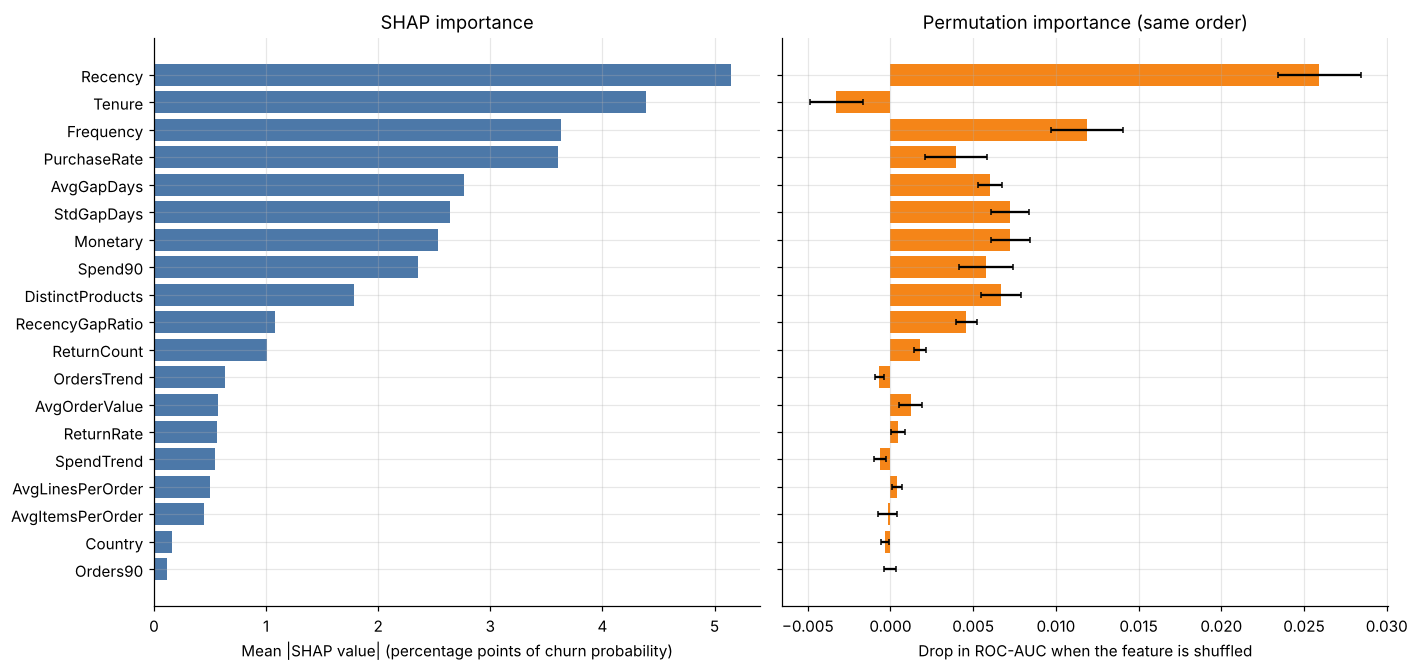

In [7]:
def permutation_importance_auc(f, Z, y, n_repeats=10, seed=SEED):
    """Drop in ROC-AUC when one feature (Country counts as one) is shuffled among the customers."""
    g = np.random.default_rng(seed)
    base_auc = roc_auc_score(y, f(Z))
    drops = np.zeros((D, n_repeats))
    for j in range(D):
        for r in range(n_repeats):
            Zp = Z.copy()
            Zp[:, j] = Z[g.permutation(len(Z)), j]
            drops[j, r] = base_auc - roc_auc_score(y, f(Zp))
    return base_auc, drops


y_test = test["Churn"].to_numpy()
auc0, drops = permutation_importance_auc(f_model, Z_test, y_test)

imp = pd.DataFrame({"Feature": FEATS,
                    "MeanAbsSHAP_pp": np.abs(pp).mean(axis=0),
                    "PermImportance_AUCdrop": drops.mean(axis=1),
                    "PermImportance_std": drops.std(axis=1)})
imp["Meaning"] = imp["Feature"].map(describe)
imp = imp.sort_values("MeanAbsSHAP_pp", ascending=False).reset_index(drop=True)
imp["RankSHAP"] = np.arange(1, D + 1)
imp["RankPerm"] = imp["PermImportance_AUCdrop"].rank(ascending=False).astype(int)

rank_corr = imp["RankSHAP"].corr(imp["RankPerm"], method="spearman")
print(f"Agreement between the SHAP ranking and the permutation ranking (Spearman): {rank_corr:.2f}\n")
display(imp[["Feature", "MeanAbsSHAP_pp", "PermImportance_AUCdrop", "RankSHAP", "RankPerm", "Meaning"]].head(12))

fig, ax = plt.subplots(1, 2, figsize=(13, 6.2))
o = imp.iloc[::-1]
ax[0].barh(o["Feature"], o["MeanAbsSHAP_pp"], color="#4C78A8")
ax[0].set_xlabel("Mean |SHAP value| (percentage points of churn probability)"); ax[0].set_title("SHAP importance")
ax[1].barh(o["Feature"], o["PermImportance_AUCdrop"], xerr=o["PermImportance_std"], color="#F58518", capsize=2)
ax[1].set_xlabel("Drop in ROC-AUC when the feature is shuffled"); ax[1].set_title("Permutation importance (same order)")
ax[1].set_yticklabels([])
plt.tight_layout(); plt.savefig(FIG / "shap_importance.png", dpi=120); plt.show()

### 7.1 Importance by behaviour group

Many features describe the same behaviour (for example `Recency`, `AvgGapDays` and `RecencyGapRatio` all say "how long since this customer last bought, compared with their usual rhythm"), and correlated features **share** the credit between them. Adding up the SHAP values inside a behaviour group gives a clearer headline for the report. (These are sums of the individual feature contributions.)

,Mean |sum of SHAP values| (pp)
Recency and purchase rhythm,8.820
Frequency and loyalty,7.420
Spend and basket size,4.300
Product range,1.790
Returns,1.480
Country,0.160


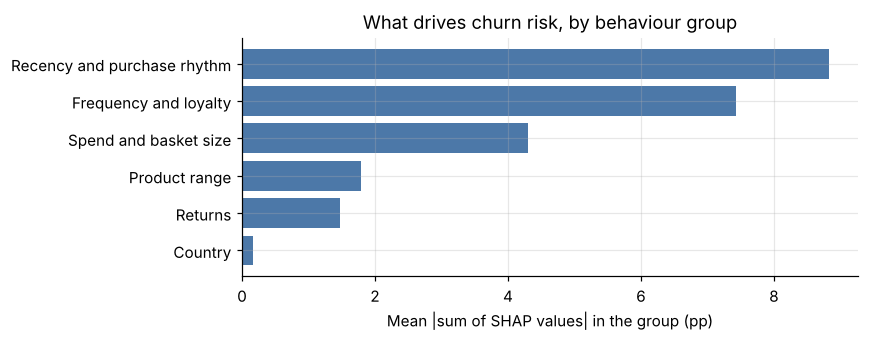

In [8]:
GROUPS = {"Recency and purchase rhythm": ["Recency", "RecencyGapRatio", "AvgGapDays", "StdGapDays"],
          "Frequency and loyalty": ["Frequency", "PurchaseRate", "Tenure", "Orders90", "OrdersTrend"],
          "Spend and basket size": ["Monetary", "AvgOrderValue", "Spend90", "SpendTrend", "AvgItemsPerOrder", "AvgLinesPerOrder"],
          "Product range": ["DistinctProducts"],
          "Returns": ["ReturnCount", "ReturnRate"],
          "Country": ["Country"]}
assert sorted(sum(GROUPS.values(), [])) == sorted(FEATS)

group_pp = pd.DataFrame({g: pp[:, [FEATS.index(f) for f in fs]].sum(axis=1) for g, fs in GROUPS.items()})
group_imp = group_pp.abs().mean().sort_values(ascending=False)
display(group_imp.round(2).to_frame("Mean |sum of SHAP values| (pp)"))

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.barh(group_imp.index[::-1], group_imp.values[::-1], color="#4C78A8")
ax.set_xlabel("Mean |sum of SHAP values| in the group (pp)"); ax.set_title("What drives churn risk, by behaviour group")
plt.tight_layout(); plt.savefig(FIG / "shap_groups.png", dpi=120); plt.show()

## 8. Direction of the effects (summary plot)

Each dot is one test customer. Left or right shows whether the feature lowers or raises that customer's churn probability. Colour shows the customer's value of the feature compared with other customers (red = high, blue = low; grey = no purchase-gap history). Features are ordered by importance. A feature with red dots on the right and blue dots on the left means "higher values raise churn risk".

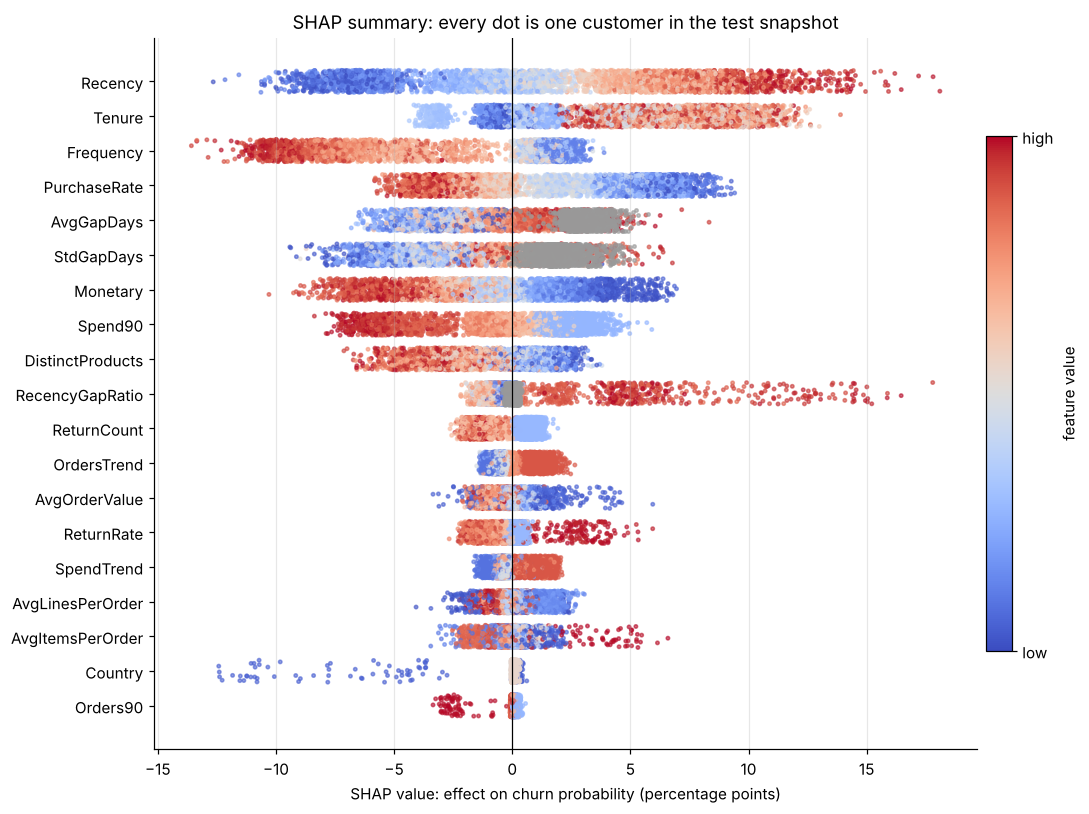

In [9]:
V = Z_test.copy()
V[:, -1] = (LEVELS[Z_test[:, -1].astype(int)] == "United Kingdom").astype(float)   # colour Country by UK (red) vs other

order = [FEATS.index(f) for f in imp["Feature"][::-1]]                               # least important first -> most important on top
fig, ax = plt.subplots(figsize=(10, 7.5))
g = np.random.default_rng(SEED)
for pos, j in enumerate(order):
    pct = pd.Series(V[:, j]).rank(pct=True).to_numpy()                               # value percentile (NaN stays NaN)
    yy = pos + g.uniform(-0.32, 0.32, len(pct))
    nan = np.isnan(pct)
    ax.scatter(pp[~nan, j], yy[~nan], c=pct[~nan], cmap="coolwarm", vmin=0, vmax=1, s=5, alpha=0.6)
    if nan.any():
        ax.scatter(pp[nan, j], yy[nan], c="#999999", s=5, alpha=0.6)
ax.axvline(0, color="k", lw=0.8)
ax.set_yticks(range(D)); ax.set_yticklabels([FEATS[j] for j in order]); ax.grid(axis="y", alpha=0)
ax.set_xlabel("SHAP value: effect on churn probability (percentage points)")
ax.set_title("SHAP summary: every dot is one customer in the test snapshot")
sm = plt.cm.ScalarMappable(cmap="coolwarm", norm=plt.Normalize(0, 1)); sm.set_array([])
cb = plt.colorbar(sm, ax=ax, pad=0.01, fraction=0.03); cb.set_ticks([0, 1]); cb.set_ticklabels(["low", "high"]); cb.set_label("feature value")
plt.tight_layout(); plt.savefig(FIG / "shap_summary.png", dpi=120); plt.show()

## 9. Plain behavioural statements

For every feature the notebook compares the customers with the **highest quarter** of the feature's values against the **lowest quarter** and reports the average SHAP value of each group, plus the rank correlation between the feature's value and its SHAP value (positive = higher value, higher churn risk). This turns the plots into sentences that can go straight into the report. Where the correlation is weak the effect is not a simple "more = worse" relationship and the dependence plot should be read instead.

Top 10 features by importance (pp = percentage points of churn probability):

* Recency (+0.95): The higher the time since the last purchase, the higher the churn risk. Customers with Recency 228 or more: +8.7 pp; with 36 or less: -6.0 pp.
* Tenure (+0.77): The higher the customer age (days since first purchase), the higher the churn risk. Customers with Tenure 515 or more: +6.8 pp; with 241 or less: -0.4 pp. CAUTION: Tenure counts days since the first purchase inside the dataset (which starts in Dec 2009), so it is cut off at about 13 months in the 2010 training snapshots; see section 10.2.
* Frequency (-0.87): The higher the number of orders, the lower the churn risk. Customers with Frequency 7 or more: -8.0 pp; with 2 or less: +1.8 pp.
* PurchaseRate (-0.92): The higher the orders per 30 days, the lower the churn risk. Customers with PurchaseRate 0.57 or more: -3.3 pp; with 0.18 or less: +6.1 pp.
* AvgGapDays (+0.66): The higher the average gap between orders, the higher the churn r

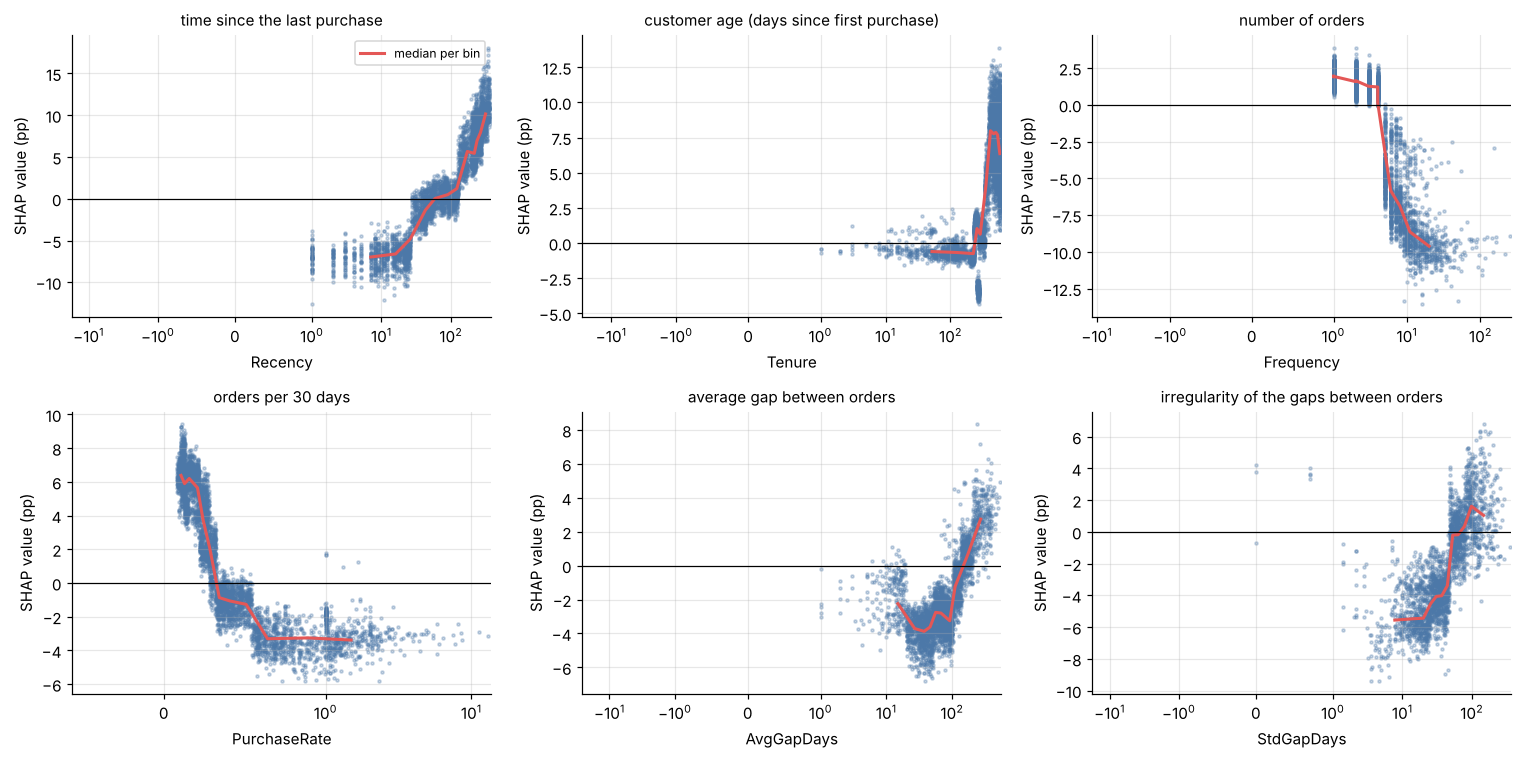

In [10]:
def fmt_num(v):
    return f"{v:,.2f}".rstrip("0").rstrip(".") if abs(v) < 100 else f"{v:,.0f}"


def direction_stats(j):
    name, ph = FEATS[j], pp[:, j]
    if name == "Country":
        uk = LEVELS[Z_test[:, j].astype(int)] == "United Kingdom"
        return {"Feature": name, "Spearman": np.nan,
                "Statement": f"UK customers ({uk.sum():,}) change churn risk by {ph[uk].mean():+.1f} pp on average, "
                             f"customers from other countries ({(~uk).sum():,}) by {ph[~uk].mean():+.1f} pp."}
    v = Z_test[:, j]
    ok = ~np.isnan(v)
    rho = pd.Series(v[ok]).corr(pd.Series(ph[ok]), method="spearman")
    q25, q75 = np.percentile(v[ok], [25, 75])
    lo = ok & (v <= q25)
    hi = ok & ((v > q75) if q25 == q75 else (v >= q75))
    hi_label = f"above {fmt_num(q75)}" if q25 == q75 else f"{fmt_num(q75)} or more"
    if abs(rho) >= 0.15:
        head = f"The higher the {FRIENDLY[name]}, the {'higher' if rho > 0 else 'lower'} the churn risk."
    else:
        head = f"No simple one-direction effect of {FRIENDLY[name]}."
    text = head
    if hi.any() and lo.any():
        text += f" Customers with {name} {hi_label}: {ph[hi].mean():+.1f} pp; with {fmt_num(q25)} or less: {ph[lo].mean():+.1f} pp."
    if (~ok).any():
        text += f" Customers with no purchase-gap history ({(~ok).sum():,}): {ph[~ok].mean():+.1f} pp."
    return {"Feature": name, "Spearman": rho, "Statement": text}


stats = pd.DataFrame([direction_stats(j) for j in range(D)]).set_index("Feature").loc[imp["Feature"]]

# features whose effect is easy to misread (see section 10.2)
CAUTIONS = {
    "Tenure": " CAUTION: Tenure counts days since the first purchase inside the dataset (which starts in Dec 2009), so it is cut off at about 13 months in the 2010 training snapshots; see section 10.2.",
    "OrdersTrend": " CAUTION: +1 means all orders fall in the last 90 days, which is typical for customers who started buying recently; read together with Frequency and Tenure.",
    "SpendTrend": " CAUTION: +1 means all spend falls in the last 90 days, which is typical for customers who started buying recently; read together with Frequency and Tenure.",
}
for k, v in CAUTIONS.items():
    stats.loc[k, "Statement"] += v
print("Top 10 features by importance (pp = percentage points of churn probability):\n")
for name, r in stats.head(10).iterrows():
    print(f"* {name} ({r['Spearman']:+.2f}): {r['Statement']}" if not np.isnan(r["Spearman"]) else f"* {name}: {r['Statement']}")

# dependence plots for the six most important features
top6 = [FEATS.index(f) for f in imp["Feature"].head(6) if f != "Country"][:6]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, j in zip(axes.ravel(), top6):
    v, ph = Z_test[:, j], pp[:, j]
    ok = ~np.isnan(v)
    ax.scatter(v[ok], ph[ok], s=4, alpha=0.3, color="#4C78A8")
    bins = pd.qcut(pd.Series(v[ok]).rank(method="first"), 12, labels=False)
    med = pd.DataFrame({"v": v[ok], "p": ph[ok], "b": bins}).groupby("b").median()
    ax.plot(med["v"], med["p"], color="#E45756", lw=2, label="median per bin")
    ax.axhline(0, color="k", lw=0.8); ax.set_xscale("symlog", linthresh=1)
    ax.set_xlabel(f"{FEATS[j]}"); ax.set_ylabel("SHAP value (pp)"); ax.set_title(FRIENDLY[FEATS[j]], fontsize=10)
axes.ravel()[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "shap_dependence.png", dpi=120); plt.show()

## 10. Second opinion from the logistic regression

The logistic regression from Step 4 is a simple model whose coefficients can be read directly (positive = higher value, higher churn odds; features are log-transformed and standardised, so sizes are comparable). If the gradient-boosting model and the logistic regression agree on the *direction* of an effect, the finding is robust and not an artefact of one algorithm. Disagreements usually occur between highly correlated features (for example `Frequency`, `PurchaseRate` and `Tenure`), where the logistic regression splits or flips the credit.

In [11]:
coef = pd.Series(lr_pipe.named_steps["clf"].coef_.ravel(), index=lr_pipe.named_steps["prep"].get_feature_names_out())
rows = []
for name in FEATS[:-1]:
    c = coef[f"num__{name}" if name in LOG_COLS else f"pas__{name}"]
    rho = stats.loc[name, "Spearman"]
    clear = abs(rho) >= 0.15
    rows.append({"Feature": name, "Logistic coefficient": c, "SHAP direction (Spearman)": rho,
                 "Agree": ("yes" if np.sign(c) == np.sign(rho) else "NO") if clear else "n/a (no simple direction)"})
agree = pd.DataFrame(rows).set_index("Feature").loc[[f for f in imp["Feature"] if f != "Country"]]
display(agree)
n_yes, n_no = (agree["Agree"] == "yes").sum(), (agree["Agree"] == "NO").sum()
print(f"Direction agrees for {n_yes} of {n_yes + n_no} features with a clear direction; disagrees for {n_no}.")
if n_no:
    print("Disagreements:", ", ".join(agree.index[agree["Agree"] == "NO"]))

,Logistic coefficient,SHAP direction (Spearman),Agree
Feature,,,
Recency,0.113,0.946,yes
Tenure,0.297,0.769,yes
Frequency,-0.599,-0.866,yes
PurchaseRate,0.411,-0.924,NO
AvgGapDays,0.369,0.659,yes
StdGapDays,0.058,0.809,yes
Monetary,-0.331,-0.900,yes
Spend90,-0.145,-0.870,yes
DistinctProducts,0.204,-0.813,NO


Direction agrees for 11 of 17 features with a clear direction; disagrees for 6.
Disagreements: PurchaseRate, DistinctProducts, AvgOrderValue, ReturnRate, SpendTrend, AvgItemsPerOrder


### 10.1 Do different customers churn for different reasons?

The table repeats the global importance separately for customers with 1, 2, 3-4 and 5 or more orders (the groups used in Step 4, where the model was weakest for one-order customers).

,"1 order (n=1,051)",2 orders (n=741),3-4 orders (n=905),"5+ orders (n=1,616)"
Recency,5.153,5.085,5.280,5.108
Tenure,1.391,3.933,5.969,5.669
Frequency,1.941,1.587,1.238,6.995
PurchaseRate,3.998,4.785,4.223,2.457
AvgGapDays,3.016,2.439,2.277,3.030
StdGapDays,2.099,1.623,2.394,3.586
Monetary,2.550,1.684,1.558,3.450
Spend90,2.261,1.920,1.665,3.011


1 order     top drivers: Recency (5.2 pp), PurchaseRate (4.0 pp), AvgGapDays (3.0 pp)
2 orders    top drivers: Recency (5.1 pp), PurchaseRate (4.8 pp), Tenure (3.9 pp)
3-4 orders  top drivers: Tenure (6.0 pp), Recency (5.3 pp), PurchaseRate (4.2 pp)
5+ orders   top drivers: Frequency (7.0 pp), Tenure (5.7 pp), Recency (5.1 pp)


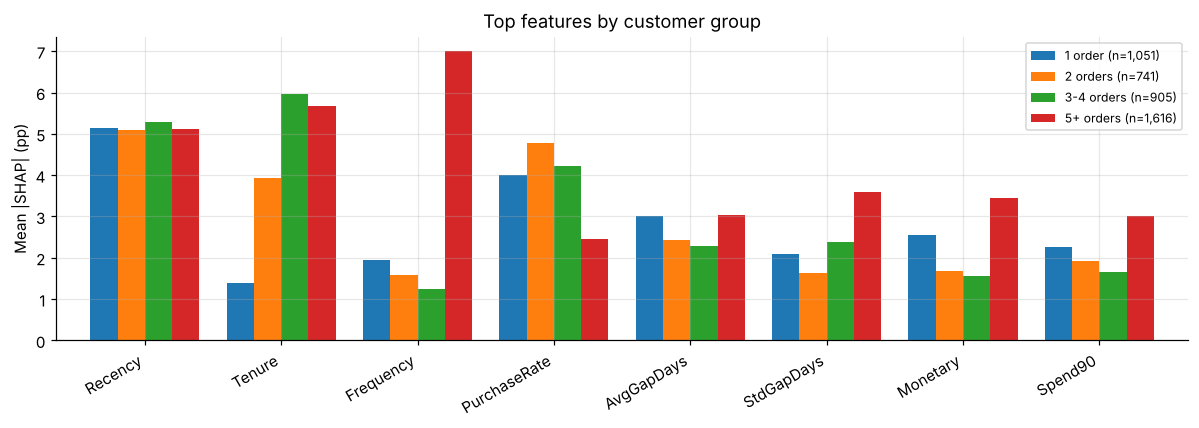

In [12]:
bucket = pd.cut(test["Frequency"], [0, 1, 2, 4, 10 ** 6], labels=["1 order", "2 orders", "3-4 orders", "5+ orders"])
top_feats = imp["Feature"].head(8).tolist()
cols = [FEATS.index(f) for f in top_feats]
by_freq = pd.DataFrame({f"{lab} (n={int((bucket == lab).sum()):,})": np.abs(pp[(bucket == lab).to_numpy()][:, cols]).mean(axis=0)
                        for lab in bucket.cat.categories}, index=top_feats)
display(by_freq)
for lab in bucket.cat.categories:
    m = (bucket == lab).to_numpy()
    top3 = pd.Series(np.abs(pp[m]).mean(axis=0), index=FEATS).sort_values(ascending=False).head(3)
    print(f"{lab:11s} top drivers: " + ", ".join(f"{k} ({v:.1f} pp)" for k, v in top3.items()))

fig, ax = plt.subplots(figsize=(11, 4))
by_freq.plot.bar(ax=ax, width=0.8); ax.set_ylabel("Mean |SHAP| (pp)"); ax.set_title("Top features by customer group")
plt.xticks(rotation=30, ha="right"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "shap_by_group.png", dpi=120); plt.show()

### 10.2 Features to read with care

SHAP explains what the **model** does, and a model can lean on a feature for reasons that do not carry over to new data. Two checks:

* **SHAP vs permutation importance.** A large gap between the two ranks means the model uses a feature in its predictions without that feature helping it to rank test customers correctly.
* **Training range.** The training snapshots are all in 2010, but `Tenure` is measured from the first purchase *inside the dataset*, which starts in December 2009. Training tenures therefore stop at about 13 months, while in mid-2011 many customers are older than that. A tree model has never seen such values and treats them like the largest value it knows.

The last cell retrains the scikit-learn boosting model with Step 4's settings, with and without `Tenure`. This is a **diagnostic on the test snapshot**, not a model choice: if `Tenure` is to be dropped, the decision should be made in Step 4 using the training snapshots only (for example by training on three of the 2010 snapshots and validating on the fourth), so that the test set stays untouched.

In [13]:
# 1) features where SHAP and permutation importance disagree strongly
gap = imp.assign(RankGap=(imp["RankSHAP"] - imp["RankPerm"]).abs())
disagree = gap[gap["RankGap"] >= 8][["Feature", "RankSHAP", "RankPerm", "MeanAbsSHAP_pp", "PermImportance_AUCdrop"]]
print("Features whose SHAP rank and permutation rank differ by 8 places or more:")
display(disagree if len(disagree) else pd.DataFrame({"note": ["none"]}))

# 2) Tenure: training range vs test range
tr_max = train["Tenure"].max()
share_beyond = (test["Tenure"] > tr_max).mean()
print(f"\nTenure (days since first purchase in the dataset): training maximum {tr_max:.0f} days, test maximum {test['Tenure'].max():.0f} days")
print(f"{share_beyond:.0%} of the test customers are older than any training customer")
display(train.groupby("SnapshotDate")["Tenure"].agg(Median="median", Max="max").T)

# 3) the trend features: how many customers sit at the +1 extreme?
at_one = test["OrdersTrend"] == 1
print(f"\nOrdersTrend = +1 (all orders in the last 90 days): {at_one.mean():.0%} of test customers; their median Tenure is {test.loc[at_one, 'Tenure'].median():.0f} days against {test['Tenure'].median():.0f} for all customers")

# 4) what-if: scikit-learn boosting with Step 4's settings, with and without Tenure (diagnostic only)
def auc_without(drop_cols):
    num = [c for c in LOG_COLS if c not in drop_cols]
    prep = ColumnTransformer([("num", SimpleImputer(strategy="median"), num), ("pas", "passthrough", PASS_COLS),
                              ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=100, sparse_output=False), CAT_COLS)])
    m = Pipeline([("prep", prep), ("clf", HistGradientBoostingClassifier(random_state=SEED, min_samples_leaf=20, max_iter=300, max_depth=3,
                                                                          learning_rate=0.03, l2_regularization=10))])
    cols = num + PASS_COLS + CAT_COLS
    m.fit(train[cols], train["Churn"])
    return roc_auc_score(test["Churn"], m.predict_proba(test[cols])[:, 1])

auc_all, auc_no_tenure = auc_without([]), auc_without(["Tenure"])
print(f"\nTest ROC-AUC, scikit-learn boosting, all features   : {auc_all:.4f}")
print(f"Test ROC-AUC, scikit-learn boosting, without Tenure : {auc_no_tenure:.4f}   (difference {auc_no_tenure - auc_all:+.4f})")

Features whose SHAP rank and permutation rank differ by 8 places or more:


,Feature,RankSHAP,RankPerm,MeanAbsSHAP_pp,PermImportance_AUCdrop
1,Tenure,2,19,4.391,-0.003



Tenure (days since first purchase in the dataset): training maximum 395 days, test maximum 577 days
48% of the test customers are older than any training customer


SnapshotDate,2010-06-30,2010-08-31,2010-10-31,2010-12-31
Median,139.000,188.000,226.000,266.000
Max,211.000,273.000,334.000,395.000



OrdersTrend = +1 (all orders in the last 90 days): 21% of test customers; their median Tenure is 324 days against 382 for all customers

Test ROC-AUC, scikit-learn boosting, all features   : 0.7752
Test ROC-AUC, scikit-learn boosting, without Tenure : 0.7838   (difference +0.0086)


## 11. Explaining individual customers

A **waterfall chart** starts at the churn probability of a typical customer and shows how each feature pushes this customer's probability up (red) or down (blue) until it reaches the model's final prediction. For individual explanations the calculation is repeated 1,000 times per customer, so the contributions are precise.

Three contrasting customers from the test snapshot are shown: the highest-spending customer in the *High* risk tier (the kind a retention team would call personally), the safest customer, and a customer flagged *High* risk who nevertheless kept buying (a false alarm worth understanding).

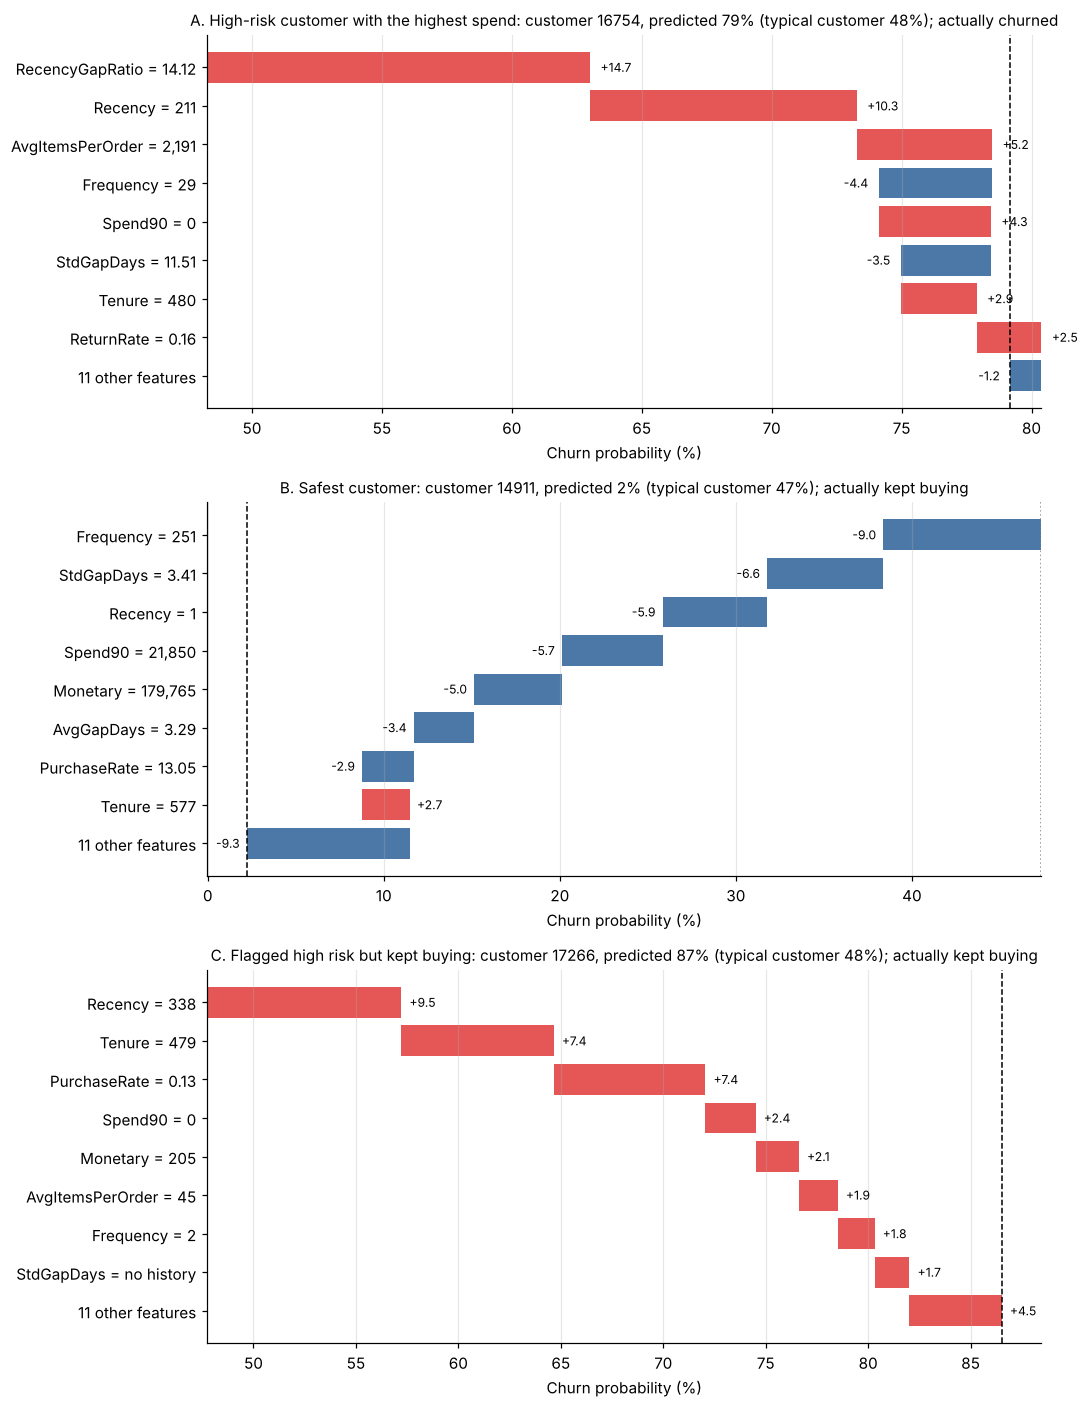


A. High-risk customer with the highest spend - customer 16754 (United Kingdom), churn probability 79%, typical customer 48%
  Raises the risk : RecencyGapRatio = 14.12 (+14.7 pp); Recency = 211 (+10.3 pp); AvgItemsPerOrder = 2,191 (+5.2 pp)
  Lowers the risk : Frequency = 29 (-4.4 pp); StdGapDays = 11.51 (-3.5 pp); PurchaseRate = 1.81 (-2.2 pp)

B. Safest customer - customer 14911 (EIRE), churn probability 2%, typical customer 47%
  Raises the risk : Tenure = 577 (+2.7 pp)
  Lowers the risk : Frequency = 251 (-9.0 pp); StdGapDays = 3.41 (-6.6 pp); Recency = 1 (-5.9 pp)

C. Flagged high risk but kept buying - customer 17266 (United Kingdom), churn probability 87%, typical customer 48%
  Raises the risk : Recency = 338 (+9.5 pp); Tenure = 479 (+7.4 pp); PurchaseRate = 0.13 (+7.4 pp)
  Lowers the risk : nothing large


In [14]:
def fmt_value(j, v):
    if FEATS[j] == "Country":
        return LEVELS[int(v)]
    return "no history" if np.isnan(v) else fmt_num(v)


row_of = {c: i for i, c in enumerate(test["CustomerID"])}
high = churn[churn["RiskTier"] == "High"]
examples = {
    "A. High-risk customer with the highest spend": high.sort_values("Monetary", ascending=False)["CustomerID"].iloc[0],
    "B. Safest customer": churn.sort_values("ChurnProbability")["CustomerID"].iloc[0],
    "C. Flagged high risk but kept buying": high[high["Churn"] == 0].sort_values("ChurnProbability", ascending=False)["CustomerID"].iloc[0],
}
idx = [row_of[c] for c in examples.values()]

# 1,000 independent repeats per customer -> precise individual explanations
X_loc = np.repeat(Z_test[idx], N_LOCAL, axis=0)
phi_l, _, base_l = shapley_sampling(f_model, X_loc, B, n_pairs=2, seed=SEED + 1)
phi_l = phi_l.reshape(len(idx), N_LOCAL, D)
phi_loc = phi_l.mean(axis=1)
se_loc = phi_l.std(axis=1) / np.sqrt(N_LOCAL)
base_loc = base_l.reshape(len(idx), N_LOCAL).mean(axis=1)
assert np.abs(base_loc + phi_loc.sum(axis=1) - p_model[idx]).max() < 1e-9

fig, axes = plt.subplots(len(idx), 1, figsize=(10, 4.3 * len(idx)))
for ax, (title, cid), k, i in zip(axes, examples.items(), range(len(idx)), idx):
    ph, z = phi_loc[k], Z_test[i]
    order_k = np.argsort(-np.abs(ph))
    show, rest = order_k[:8], order_k[8:]
    labels = [f"{FEATS[j]} = {fmt_value(j, z[j])}" for j in show]
    vals = [ph[j] * 100 for j in show]
    if len(rest):
        labels.append(f"{len(rest)} other features"); vals.append(ph[rest].sum() * 100)
    left = base_loc[k] * 100
    for r, v in enumerate(vals):
        ax.barh(r, v, left=left, color="#E45756" if v > 0 else "#4C78A8")
        ax.text(left + v + (0.4 if v > 0 else -0.4), r, f"{v:+.1f}", va="center", ha="left" if v > 0 else "right", fontsize=8)
        left += v
    ax.axvline(base_loc[k] * 100, color="grey", ls=":", lw=1); ax.axvline(p_model[i] * 100, color="k", ls="--", lw=1)
    ax.set_yticks(range(len(vals))); ax.set_yticklabels(labels); ax.invert_yaxis(); ax.grid(axis="y", alpha=0)
    actual = "churned" if y_test[i] else "kept buying"
    ax.set_title(f"{title}: customer {cid}, predicted {p_model[i]:.0%} (typical customer {base_loc[k]:.0%}); actually {actual}", fontsize=10)
    ax.set_xlabel("Churn probability (%)")
plt.tight_layout(); plt.savefig(FIG / "shap_waterfalls.png", dpi=120); plt.show()

for k, (title, cid) in enumerate(examples.items()):
    i, ph, z = idx[k], phi_loc[k] * 100, Z_test[idx[k]]
    up = [j for j in np.argsort(-ph) if ph[j] >= 1][:3]
    dn = [j for j in np.argsort(ph) if ph[j] <= -1][:3]
    r = churn.iloc[i]
    print(f"\n{title} - customer {cid} ({r['Country']}), churn probability {p_model[i]:.0%}, typical customer {base_loc[k]:.0%}")
    print("  Raises the risk : " + ("; ".join(f"{FEATS[j]} = {fmt_value(j, z[j])} ({ph[j]:+.1f} pp)" for j in up) or "nothing large"))
    print("  Lowers the risk : " + ("; ".join(f"{FEATS[j]} = {fmt_value(j, z[j])} ({ph[j]:+.1f} pp)" for j in dn) or "nothing large"))

## 12. Optional: cross-check with the `shap` library

If the `shap` library is installed (`pip install shap`), this cell recomputes SHAP values for 150 customers with the library's own permutation explainer and compares them with the values above. High agreement confirms the calculation; the library can also draw its standard plots from the values computed here. If `shap` is missing the cell prints a message and stops; nothing else depends on it.

In [15]:
try:
    import shap

    sel = np.random.default_rng(SEED).choice(len(Z_test), 150, replace=False)
    explainer = shap.Explainer(f_model, B, algorithm="permutation")
    lib = explainer(Z_test[sel], max_evals=2 * D * 25 + 1)
    r_all = np.corrcoef(lib.values.ravel(), phi[sel].ravel())[0, 1]
    mean_lib = pd.Series(np.abs(lib.values).mean(axis=0), index=FEATS)
    mean_mine = pd.Series(np.abs(phi[sel]).mean(axis=0), index=FEATS)
    print(f"shap {shap.__version__}: correlation with this notebook's SHAP values on 150 customers = {r_all:.3f}")
    print(f"Rank correlation of mean |SHAP| across features = {mean_lib.corr(mean_mine, method='spearman'):.3f}")

    expl = shap.Explanation(values=pp, base_values=base_row * 100, data=Z_test, feature_names=FEATS)
    shap.plots.beeswarm(expl, show=True)                     # the library's standard summary plot of the values computed above
except ImportError:
    print("The 'shap' library is not installed - skipping this optional cross-check (pip install shap).")
except Exception as e:
    print("Optional cross-check skipped:", type(e).__name__, str(e)[:200])

The 'shap' library is not installed - skipping this optional cross-check (pip install shap).


## 13. Save results for the next steps

* `shap_values_test.csv` - one row per test customer: probability, base value and the SHAP value of every feature (in probability units, so `ChurnProbability = BaseValue + sum of the SHAP_ columns`).
* `shap_feature_importance.csv` - global importance, direction statements and agreement with the logistic regression (for the report).
* `shap_top_drivers_test.csv` - the main reasons per customer in words, ready for the retention action list (Step 8) and the customer-profile page of the dashboard (Step 10). Only contributions of at least 0.5 pp are listed, because smaller ones are within the sampling noise.

In [16]:
# 1) full SHAP values
shap_df = pd.DataFrame(phi, columns=[f"SHAP_{f}" for f in FEATS])
shap_df.insert(0, "BaseValue", base_row)
shap_df.insert(0, "ChurnProbability", p_model)
shap_df.insert(0, "SnapshotDate", test["SnapshotDate"].dt.strftime("%Y-%m-%d"))
shap_df.insert(0, "CustomerID", test["CustomerID"].to_numpy())
assert np.allclose(shap_df["BaseValue"] + shap_df[[f"SHAP_{f}" for f in FEATS]].sum(axis=1), shap_df["ChurnProbability"])
shap_df.to_csv(DATA / "shap_values_test.csv", index=False)

# 2) importance table with statements
out = imp.drop(columns=["Meaning"]).copy()
out.insert(1, "Meaning", imp["Meaning"])
out["Spearman_value_vs_SHAP"] = out["Feature"].map(stats["Spearman"])
out["Statement"] = out["Feature"].map(stats["Statement"])
out["LogisticAgrees"] = out["Feature"].map(agree["Agree"]).fillna("n/a")
out.to_csv(DATA / "shap_feature_importance.csv", index=False)

# 3) reasons per customer, in words
def reason(j, i):
    return f"{FEATS[j]} = {fmt_value(j, Z_test[i, j])} ({pp[i, j]:+.0f} pp)"

rows = []
for i in range(len(test)):
    ph = pp[i]
    ups = [j for j in np.argsort(-ph) if ph[j] >= 0.5][:3]
    dns = [j for j in np.argsort(ph) if ph[j] <= -0.5][:2]
    rec = {"CustomerID": test["CustomerID"].iloc[i], "ChurnProbability": p_model[i], "RiskTier": churn["RiskTier"].iloc[i]}
    for k in range(3):
        rec[f"RiskDriver{k + 1}"] = FEATS[ups[k]] if k < len(ups) else ""
        rec[f"RiskDriver{k + 1}_pp"] = ph[ups[k]] if k < len(ups) else np.nan
    for k in range(2):
        rec[f"Protective{k + 1}"] = FEATS[dns[k]] if k < len(dns) else ""
        rec[f"Protective{k + 1}_pp"] = ph[dns[k]] if k < len(dns) else np.nan
    rec["WhyAtRisk"] = "; ".join(reason(j, i) for j in ups)
    rec["WhyProtected"] = "; ".join(reason(j, i) for j in dns)
    rows.append(rec)
drivers = pd.DataFrame(rows)
drivers.to_csv(DATA / "shap_top_drivers_test.csv", index=False)

for f in ("shap_values_test.csv", "shap_feature_importance.csv", "shap_top_drivers_test.csv"):
    print(f"saved data/{f}  ({(DATA / f).stat().st_size / 1e6:.2f} MB)")
print("\nExample rows of shap_top_drivers_test.csv (highest-risk customers):")
display(drivers.sort_values("ChurnProbability", ascending=False).head(4)[["CustomerID", "ChurnProbability", "RiskTier", "WhyAtRisk", "WhyProtected"]])

saved data/shap_values_test.csv  (1.99 MB)
saved data/shap_feature_importance.csv  (0.01 MB)
saved data/shap_top_drivers_test.csv  (1.19 MB)

Example rows of shap_top_drivers_test.csv (highest-risk customers):


,CustomerID,ChurnProbability,RiskTier,WhyAtRisk,WhyProtected
1795,14833,0.879,High,Recency = 337 (+10 pp); PurchaseRate = 0.09 (+6 pp); Tenure = 337 (+4 pp),
1960,15056,0.868,High,Recency = 359 (+11 pp); PurchaseRate = 0.08 (+7 pp); Tenure = 359 (+5 pp),
2534,15851,0.866,High,Recency = 365 (+10 pp); PurchaseRate = 0.08 (+6 pp); Tenure = 365 (+5 pp),
3546,17224,0.866,High,Recency = 340 (+11 pp); PurchaseRate = 0.09 (+6 pp); Tenure = 340 (+4 pp),


## 14. Summary of findings

In [17]:
top5 = imp.head(5)
lines = [
    f"Model explained: {BEST} ({source.split(' (')[0]}); test snapshot {test['SnapshotDate'].iloc[0]:%d %b %Y}, {len(test):,} customers; typical churn probability {base_row.mean():.2f}.",
    "Most important features (mean |SHAP|, pp of churn probability): " + ", ".join(f"{r.Feature} {r.MeanAbsSHAP_pp:.1f}" for r in top5.itertuples()) + ".",
    f"Most important behaviour groups: " + ", ".join(f"{g} {v:.1f} pp" for g, v in group_imp.head(3).items()) + ".",
    f"SHAP ranking agrees with permutation importance (Spearman {rank_corr:.2f}); logistic regression agrees on direction for {n_yes} of {n_yes + n_no} features with a clear direction.",
]
for name, r in stats.head(5).iterrows():
    lines.append(f"{name}: {r['Statement']}")
for lab in bucket.cat.categories:
    m = (bucket == lab).to_numpy()
    t = pd.Series(np.abs(pp[m]).mean(axis=0), index=FEATS).sort_values(ascending=False).head(2)
    lines.append(f"Customers with {lab}: main drivers {t.index[0]} and {t.index[1]}.")
lines.append(f"Caution - Tenure: SHAP rank {int(imp.loc[imp.Feature == 'Tenure', 'RankSHAP'].iloc[0])} but permutation rank {int(imp.loc[imp.Feature == 'Tenure', 'RankPerm'].iloc[0])}; "
             f"{share_beyond:.0%} of test customers are older than any training customer (training max {tr_max:.0f} days, test max {test['Tenure'].max():.0f}); "
             f"diagnostic test ROC-AUC {auc_all:.3f} with Tenure vs {auc_no_tenure:.3f} without. Any decision to drop it belongs in Step 4 using training snapshots only.")
lines.append(f"Calculation checks: additivity error {add_err:.0e}; exact check on the logistic regression error {err:.0e}; sampling noise {se.mean() * 100:.2f} pp per value, {se.mean() * 100 / np.sqrt(len(Z_test)):.3f} pp in global averages.")

print("KEY FINDINGS")
print("=" * 60)
for i, l in enumerate(lines, 1):
    print(f"{i}. {l}")
Path("shap_summary.txt").write_text("\n".join(f"{i}. {l}" for i, l in enumerate(lines, 1)), encoding="utf-8")
print("\nSaved shap_summary.txt")

KEY FINDINGS
1. Model explained: Gradient Boosting (sklearn) (RETRAINED copy of the Step 4 models); test snapshot 01 Jul 2011, 4,313 customers; typical churn probability 0.48.
2. Most important features (mean |SHAP|, pp of churn probability): Recency 5.2, Tenure 4.4, Frequency 3.6, PurchaseRate 3.6, AvgGapDays 2.8.
3. Most important behaviour groups: Recency and purchase rhythm 8.8 pp, Frequency and loyalty 7.4 pp, Spend and basket size 4.3 pp.
4. SHAP ranking agrees with permutation importance (Spearman 0.61); logistic regression agrees on direction for 11 of 17 features with a clear direction.
5. Recency: The higher the time since the last purchase, the higher the churn risk. Customers with Recency 228 or more: +8.7 pp; with 36 or less: -6.0 pp.
6. Tenure: The higher the customer age (days since first purchase), the higher the churn risk. Customers with Tenure 515 or more: +6.8 pp; with 241 or less: -0.4 pp. CAUTION: Tenure counts days since the first purchase inside the dataset (whi

## How to use these results

**For the report**
* Quote the global importance and the behaviour groups, and the sentences from section 9, as the answer to *why do customers churn*. State that SHAP shows what the **model** relies on to predict churn, which is evidence of association, not proof that changing a feature would cause customers to stay.
* Correlated features share credit (for example `Recency`, `RecencyGapRatio` and `AvgGapDays`; or `Frequency`, `PurchaseRate` and `Tenure`), so read them as groups. SHAP also assumes features can be switched independently, which can produce unrealistic combinations for strongly linked features.
* Results are for one test snapshot (1 July 2011) and one 150-day window.

**For Step 8 (retention framework) and Step 10 (dashboard)**
* `data/shap_top_drivers_test.csv` gives the main reasons per customer (`WhyAtRisk`, `WhyProtected`), so an action can say *why* a customer is at risk (for example "long time since last purchase" vs "falling order frequency") and choose the offer accordingly.
* `data/shap_values_test.csv` has the full contributions for the customer-profile page; join on `CustomerID`.
* Explaining customers outside the test snapshot (for example those active today) needs the same calculation on their feature rows: reuse `to_array`, `to_frame`, `f_model` and `shapley_sampling` from this notebook.